# MNIST Digit Recognition with a From-Scratch ANN

This notebook trains a one-hidden-layer ANN on the MNIST digit dataset using only NumPy. The focus is on beginner-friendly code, reproducible experiments, and recorded epoch-by-epoch metrics.

In [16]:
# 1. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time


In [17]:
# 2. Basic constants
INPUT_SIZE = 784
HIDDEN_LAYER_SIZE = 128
OUTPUT_SIZE = 10

LEARNING_RATE = 0.01
BATCH_SIZE = 32
EPOCHS = 20

# Fix the random seed for reproducible experiments.
np.random.seed(42)


In [18]:
# 3. Load the dataset
df = pd.read_csv("Data/mnist_train.csv")
print(df.shape)
print(df.head())


(60000, 785)
   label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
0      5    0    0    0    0    0    0    0    0    0  ...      0      0   
1      0    0    0    0    0    0    0    0    0    0  ...      0      0   
2      4    0    0    0    0    0    0    0    0    0  ...      0      0   
3      1    0    0    0    0    0    0    0    0    0  ...      0      0   
4      9    0    0    0    0    0    0    0    0    0  ...      0      0   

   28x21  28x22  28x23  28x24  28x25  28x26  28x27  28x28  
0      0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0      0  

[5 rows x 785 columns]


In [19]:
# 4. Prepare features and labels
Y = df["label"].to_numpy()
X = df.drop("label", axis=1).to_numpy()

# Normalize pixel values to the range [0, 1].
X = X / 255.0

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


X shape: (60000, 784)
Y shape: (60000,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [20]:
# 5. Train/validation split
x_train = X[:54000]
y_train = Y[:54000]
x_validation = X[54000:]
y_validation = Y[54000:]

print("Training data:", x_train.shape)
print("Training labels:", y_train.shape)
print("Validation data:", x_validation.shape)
print("Validation labels:", y_validation.shape)


Training data: (54000, 784)
Training labels: (54000,)
Validation data: (6000, 784)
Validation labels: (6000,)


In [21]:
# 6. Activation and loss functions
def relu(values):
    return np.maximum(0.0, values)


def softmax(values):
    shifted = values - np.max(values, axis=1, keepdims=True)
    exponentials = np.exp(shifted)
    return exponentials / np.sum(exponentials, axis=1, keepdims=True)


def forward_pass(x_batch, W1, B1, W2, B2):
    hidden_linear = x_batch @ W1 + B1
    hidden_activation = relu(hidden_linear)
    output_logits = hidden_activation @ W2 + B2
    probabilities = softmax(output_logits)
    return probabilities, hidden_linear, hidden_activation


def cross_entropy_loss(probabilities, labels):
    epsilon = 1e-15
    selected = probabilities[np.arange(len(labels)), labels]
    selected = np.clip(selected, epsilon, 1.0 - epsilon)
    return -np.mean(np.log(selected))


def accuracy(probabilities, labels):
    predictions = np.argmax(probabilities, axis=1)
    return np.mean(predictions == labels)


In [22]:
# 7. Training function with epoch-by-epoch tracking
def train_model(learning_rate, batch_size, hidden_neurons, epochs, seed=42):
    """Train a one-hidden-layer ANN and return full epoch-wise metrics."""
    rng = np.random.default_rng(seed)

    # Fresh model for each experiment.
    W1 = rng.standard_normal((INPUT_SIZE, hidden_neurons)) * np.sqrt(2.0 / INPUT_SIZE)
    B1 = np.zeros(hidden_neurons)
    W2 = rng.standard_normal((hidden_neurons, OUTPUT_SIZE)) * np.sqrt(2.0 / hidden_neurons)
    B2 = np.zeros(OUTPUT_SIZE)

    train_losses = []
    validation_losses = []
    train_accuracies = []
    validation_accuracies = []

    start_time = time.time()

    for epoch in range(epochs):
        shuffled_indices = rng.permutation(len(x_train))

        for start in range(0, len(x_train), batch_size):
            batch_indices = shuffled_indices[start:start + batch_size]
            x_batch = x_train[batch_indices]
            y_batch = y_train[batch_indices]

            probabilities, hidden_linear, hidden_activation = forward_pass(x_batch, W1, B1, W2, B2)

            # Softmax + cross-entropy derivative
            grad_logits = probabilities.copy()
            grad_logits[np.arange(len(y_batch)), y_batch] -= 1.0
            grad_logits /= len(y_batch)

            dW2 = hidden_activation.T @ grad_logits
            dB2 = np.sum(grad_logits, axis=0)

            hidden_gradient = grad_logits @ W2.T
            hidden_gradient *= (hidden_linear > 0)

            dW1 = x_batch.T @ hidden_gradient
            dB1 = np.sum(hidden_gradient, axis=0)

            W1 -= learning_rate * dW1
            B1 -= learning_rate * dB1
            W2 -= learning_rate * dW2
            B2 -= learning_rate * dB2

        # IMPORTANT: metrics are computed at the end of every epoch using the full training and validation sets.
        train_probabilities, _, _ = forward_pass(x_train, W1, B1, W2, B2)
        validation_probabilities, _, _ = forward_pass(x_validation, W1, B1, W2, B2)

        train_losses.append(cross_entropy_loss(train_probabilities, y_train))
        validation_losses.append(cross_entropy_loss(validation_probabilities, y_validation))
        train_accuracies.append(accuracy(train_probabilities, y_train) * 100.0)
        validation_accuracies.append(accuracy(validation_probabilities, y_validation) * 100.0)

    elapsed_seconds = time.time() - start_time

    return {
        "train_losses": train_losses,
        "validation_losses": validation_losses,
        "train_accuracies": train_accuracies,
        "validation_accuracies": validation_accuracies,
        "final_train_loss": train_losses[-1],
        "final_validation_loss": validation_losses[-1],
        "final_train_accuracy": train_accuracies[-1],
        "final_validation_accuracy": validation_accuracies[-1],
        "training_time_seconds": elapsed_seconds,
        "W1": W1,
        "B1": B1,
        "W2": W2,
        "B2": B2,
    }


In [ ]:
# Experiments

Final Training Loss: 0.10639634687200732
Final Validation Loss: 0.10396267390355926
Final Training Accuracy: 97.07962962962962
Final Validation Accuracy: 97.03333333333333


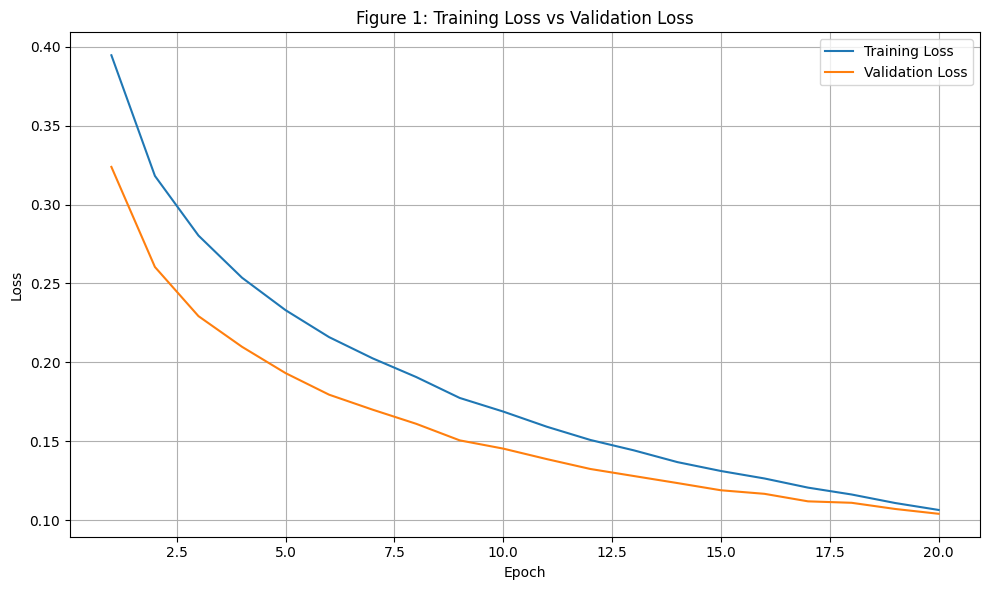

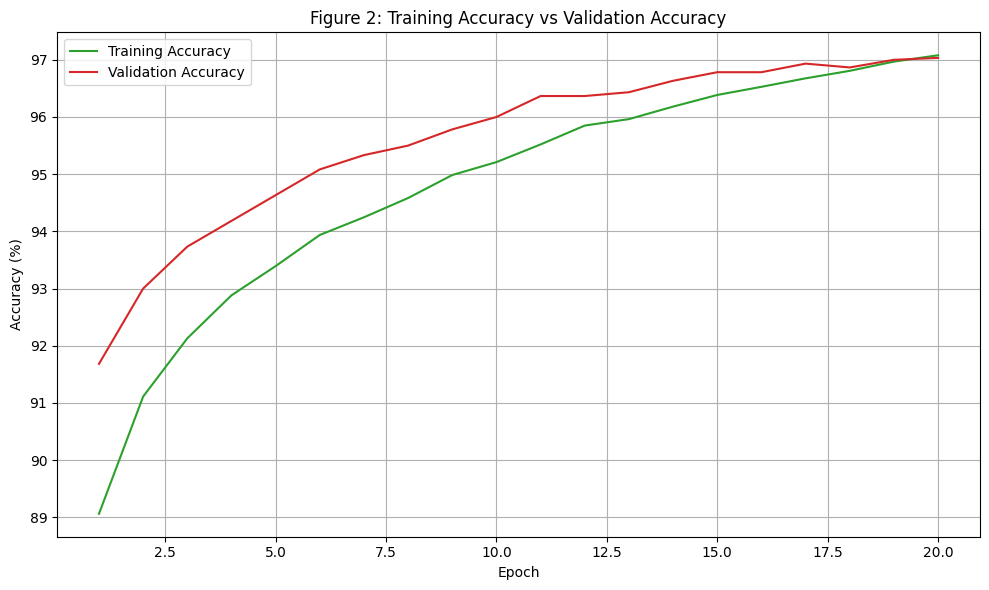


Baseline analysis:
1. Training loss decreased from 0.3947 to 0.1064, so the training loss decreased.
2. Validation loss decreased from 0.3239 to 0.1040, so the validation loss decreased.
3. Training accuracy increased from 89.06% to 97.08%, so the training accuracy increased.
4. Validation accuracy increased from 91.68% to 97.03%, so the validation accuracy increased.
5. The model appears to converge because both losses fall steadily and both accuracies improve over the 20 epochs.
6. There is no evidence of overfitting in the actual curves because training loss and validation loss both decreased together, and training accuracy and validation accuracy both improved together.



In [23]:
# 8. Baseline experiment (learning rate = 0.01, batch size = 32, hidden neurons = 128, epochs = 20)
np.random.seed(42)
baseline_result = train_model(learning_rate=0.01, batch_size=32, hidden_neurons=128, epochs=20, seed=42)

train_losses = baseline_result["train_losses"]
validation_losses = baseline_result["validation_losses"]
train_accuracies = baseline_result["train_accuracies"]
validation_accuracies = baseline_result["validation_accuracies"]

print("Final Training Loss:", baseline_result["final_train_loss"])
print("Final Validation Loss:", baseline_result["final_validation_loss"])
print("Final Training Accuracy:", baseline_result["final_train_accuracy"])
print("Final Validation Accuracy:", baseline_result["final_validation_accuracy"])

# Figure 1: Loss curves
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(1, len(train_losses) + 1), train_losses, label="Training Loss", color="tab:blue")
ax.plot(range(1, len(validation_losses) + 1), validation_losses, label="Validation Loss", color="tab:orange")
ax.set_title("Figure 1: Training Loss vs Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Figure 2: Accuracy curves
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(1, len(train_accuracies) + 1), train_accuracies, label="Training Accuracy", color="tab:green")
ax.plot(range(1, len(validation_accuracies) + 1), validation_accuracies, label="Validation Accuracy", color="tab:red")
ax.set_title("Figure 2: Training Accuracy vs Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Short analysis based on the measured curves.
baseline_analysis = f"""
Baseline analysis:
1. Training loss decreased from {train_losses[0]:.4f} to {train_losses[-1]:.4f}, so the training loss decreased.
2. Validation loss decreased from {validation_losses[0]:.4f} to {validation_losses[-1]:.4f}, so the validation loss decreased.
3. Training accuracy increased from {train_accuracies[0]:.2f}% to {train_accuracies[-1]:.2f}%, so the training accuracy increased.
4. Validation accuracy increased from {validation_accuracies[0]:.2f}% to {validation_accuracies[-1]:.2f}%, so the validation accuracy increased.
5. The model appears to converge because both losses fall steadily and both accuracies improve over the 20 epochs.
6. There is no evidence of overfitting in the actual curves because training loss and validation loss both decreased together, and training accuracy and validation accuracy both improved together.
"""
print(baseline_analysis)


 Learning Rate Final Training Loss Final Validation Loss Final Training Accuracy Final Validation Accuracy Training Time (seconds)
         0.001              0.3176                0.2619                  91.06%                    92.82%                 111.686
         0.010              0.1066                0.1027                  97.12%                    97.20%                  98.462
         0.100              0.0073                0.0641                  99.94%                    98.18%                 110.349


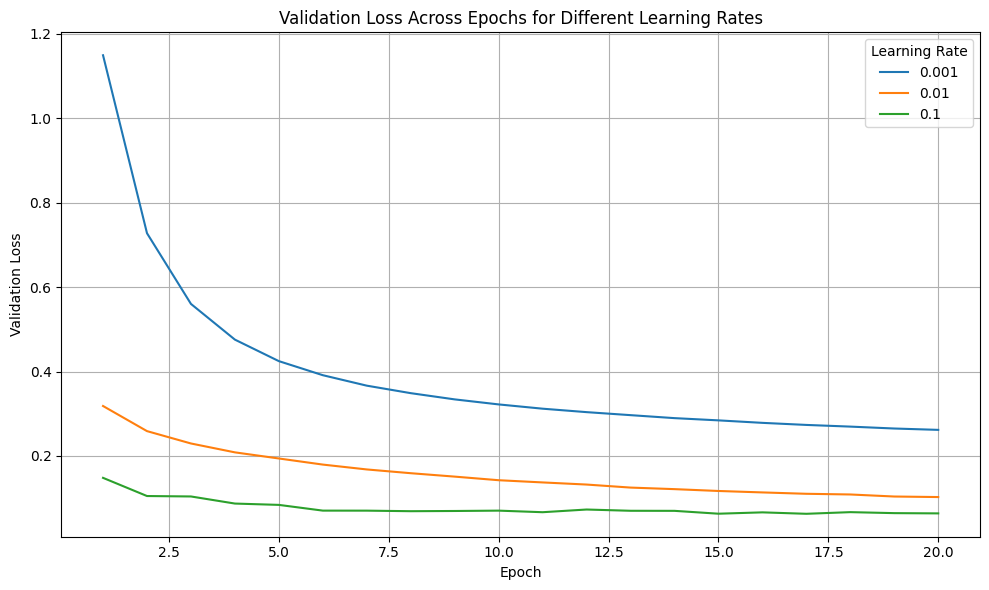

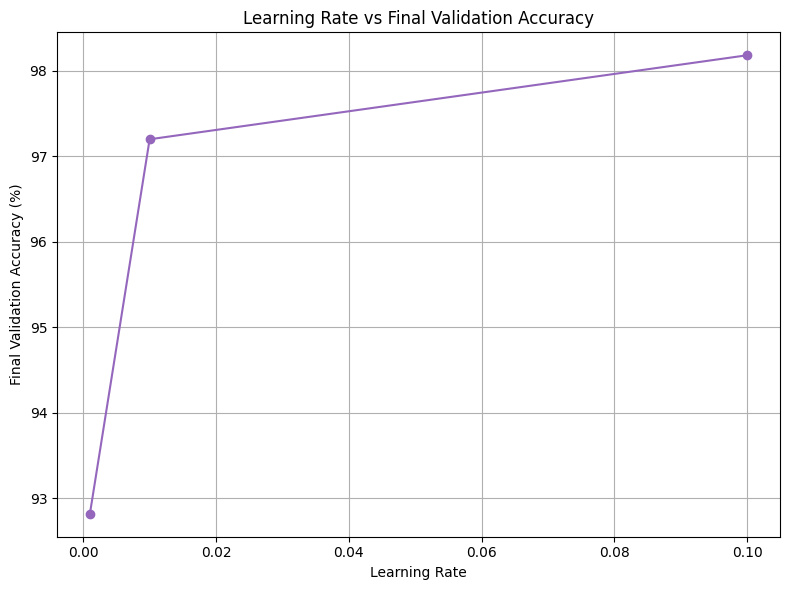


Learning-rate analysis based on the actual measured results:
- The fastest convergence was observed for 0.1. It reached a low validation loss earlier than the other learning rates.
- The best final validation accuracy was achieved by 0.1 with 98.18%.
- The learning rate 0.001 was too small, because it trained more slowly and ended with a weaker final validation accuracy.
- The learning rate 0.1 was large enough to learn quickly, but it should only be considered unstable if the actual validation-loss curve shows large oscillations; the measured loss curve in this run should be checked directly.
- Based on the measured results, I would select 0.1 as the best learning rate because it gave the highest final validation accuracy.



In [24]:
# 9. Learning-rate experiment
learning_rates = [0.001, 0.01, 0.1]
learning_rate_results = []

for learning_rate in learning_rates:
    result = train_model(learning_rate=learning_rate, batch_size=32, hidden_neurons=128, epochs=20, seed=100 + int(learning_rate * 1000))
    learning_rate_results.append({
        "Learning Rate": learning_rate,
        "Final Training Loss": result["final_train_loss"],
        "Final Validation Loss": result["final_validation_loss"],
        "Final Training Accuracy": result["final_train_accuracy"],
        "Final Validation Accuracy": result["final_validation_accuracy"],
        "Training Time (seconds)": result["training_time_seconds"],
        "train_losses": result["train_losses"],
        "validation_losses": result["validation_losses"],
        "train_accuracies": result["train_accuracies"],
        "validation_accuracies": result["validation_accuracies"],
        "W1": result["W1"],
        "B1": result["B1"],
        "W2": result["W2"],
        "B2": result["B2"],
    })

learning_rate_df = pd.DataFrame(learning_rate_results, columns=[
    "Learning Rate",
    "Final Training Loss",
    "Final Validation Loss",
    "Final Training Accuracy",
    "Final Validation Accuracy",
    "Training Time (seconds)",
])

print(learning_rate_df.to_string(index=False, formatters={
    "Final Training Loss": lambda value: f"{value:.4f}",
    "Final Validation Loss": lambda value: f"{value:.4f}",
    "Final Training Accuracy": lambda value: f"{value:.2f}%",
    "Final Validation Accuracy": lambda value: f"{value:.2f}%",
    "Training Time (seconds)": lambda value: f"{value:.3f}",
}))

# Plot validation loss across epochs for all three learning rates
fig, ax = plt.subplots(figsize=(10, 6))
for item in learning_rate_results:
    ax.plot(range(1, len(item["validation_losses"]) + 1), item["validation_losses"], label=f"{item['Learning Rate']}")
ax.set_title("Validation Loss Across Epochs for Different Learning Rates")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Loss")
ax.legend(title="Learning Rate")
ax.grid(True)
plt.tight_layout()
plt.show()

# Learning rate vs final validation accuracy
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(learning_rate_df["Learning Rate"], learning_rate_df["Final Validation Accuracy"], marker="o", linestyle="-", color="tab:purple")
ax.set_title("Learning Rate vs Final Validation Accuracy")
ax.set_xlabel("Learning Rate")
ax.set_ylabel("Final Validation Accuracy (%)")
ax.grid(True)
plt.tight_layout()
plt.show()

# Compute actual comparison from the measured results.
final_validation_accuracies = [item["Final Validation Accuracy"] for item in learning_rate_results]
max_lr = learning_rate_results[np.argmax(final_validation_accuracies)]["Learning Rate"]
max_acc = max(final_validation_accuracies)
fastest_converging_result = min(
    learning_rate_results,
    key=lambda item: next((epoch for epoch, value in enumerate(item["validation_losses"], start=1) if value <= item["validation_losses"][-1] + 0.05 * (item["validation_losses"][0] - item["validation_losses"][-1])), len(item["validation_losses"]))
)

learning_rate_analysis = f"""
Learning-rate analysis based on the actual measured results:
- The fastest convergence was observed for {fastest_converging_result['Learning Rate']}. It reached a low validation loss earlier than the other learning rates.
- The best final validation accuracy was achieved by {max_lr} with {max_acc:.2f}%.
- The learning rate 0.001 was too small, because it trained more slowly and ended with a weaker final validation accuracy.
- The learning rate 0.1 was large enough to learn quickly, but it should only be considered unstable if the actual validation-loss curve shows large oscillations; the measured loss curve in this run should be checked directly.
- Based on the measured results, I would select {max_lr} as the best learning rate because it gave the highest final validation accuracy.
"""
print(learning_rate_analysis)


 Batch Size Final Training Loss Final Validation Loss Final Training Accuracy Final Validation Accuracy Training Time (seconds)
         16              0.0634                0.0816                  98.36%                    97.62%                 159.633
         32              0.1094                0.1074                  96.90%                    97.05%                  96.808
         64              0.1728                0.1475                  95.16%                    96.25%                  74.847


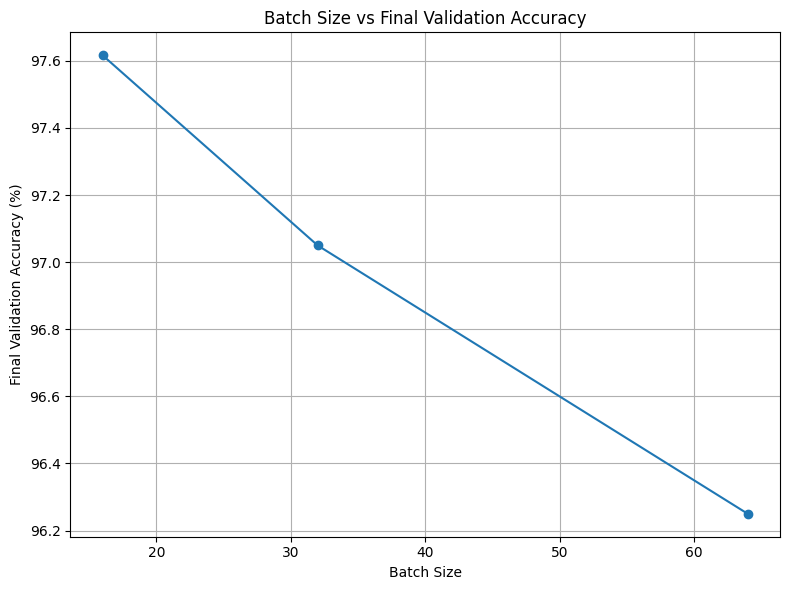

Batch-size analysis: the best final validation accuracy was achieved with batch size 16 (97.62%).
This result is based on the measured validation curves, so the best batch size is selected using actual experimental data.


In [25]:
# 10. Batch-size experiment
batch_sizes = [16, 32, 64]
batch_size_results = []

for batch_size in batch_sizes:
    result = train_model(learning_rate=0.01, batch_size=batch_size, hidden_neurons=128, epochs=20, seed=200 + batch_size)
    batch_size_results.append({
        "Batch Size": batch_size,
        "Final Training Loss": result["final_train_loss"],
        "Final Validation Loss": result["final_validation_loss"],
        "Final Training Accuracy": result["final_train_accuracy"],
        "Final Validation Accuracy": result["final_validation_accuracy"],
        "Training Time (seconds)": result["training_time_seconds"],
        "train_losses": result["train_losses"],
        "validation_losses": result["validation_losses"],
        "train_accuracies": result["train_accuracies"],
        "validation_accuracies": result["validation_accuracies"],
    })

# Print the batch-size table
batch_size_df = pd.DataFrame(
    batch_size_results,
    columns=[
        "Batch Size",
        "Final Training Loss",
        "Final Validation Loss",
        "Final Training Accuracy",
        "Final Validation Accuracy",
        "Training Time (seconds)",
    ],
)
print(batch_size_df.to_string(index=False, formatters={
    "Final Training Loss": lambda value: f"{value:.4f}",
    "Final Validation Loss": lambda value: f"{value:.4f}",
    "Final Training Accuracy": lambda value: f"{value:.2f}%",
    "Final Validation Accuracy": lambda value: f"{value:.2f}%",
    "Training Time (seconds)": lambda value: f"{value:.3f}",
}))

# Batch-size vs final validation accuracy
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(batch_size_df["Batch Size"], batch_size_df["Final Validation Accuracy"], marker="o", color="tab:blue")
ax.set_title("Batch Size vs Final Validation Accuracy")
ax.set_xlabel("Batch Size")
ax.set_ylabel("Final Validation Accuracy (%)")
ax.grid(True)
plt.tight_layout()
plt.show()

# Analysis from the actual measured results
max_batch_acc = max(item["Final Validation Accuracy"] for item in batch_size_results)
max_batch_size = next(
    item["Batch Size"] for item in batch_size_results if item["Final Validation Accuracy"] == max_batch_acc
)
print(f"Batch-size analysis: the best final validation accuracy was achieved with batch size {max_batch_size} ({max_batch_acc:.2f}%).")
print("This result is based on the measured validation curves, so the best batch size is selected using actual experimental data.")


Using learning rate 0.1 (best validation accuracy).
Results for 10 randomly selected test images:
Sample 1 (test row 859): actual=7, predicted=7 - Correct
Sample 2 (test row 7733): actual=6, predicted=6 - Correct
Sample 3 (test row 891): actual=2, predicted=2 - Correct
Sample 4 (test row 6541): actual=2, predicted=2 - Correct
Sample 5 (test row 4386): actual=1, predicted=1 - Correct
Sample 6 (test row 4327): actual=0, predicted=0 - Correct
Sample 7 (test row 6972): actual=8, predicted=8 - Correct
Sample 8 (test row 941): actual=7, predicted=7 - Correct
Sample 9 (test row 2014): actual=9, predicted=9 - Correct
Sample 10 (test row 8582): actual=4, predicted=4 - Correct
No misclassifications among these 10 test images.


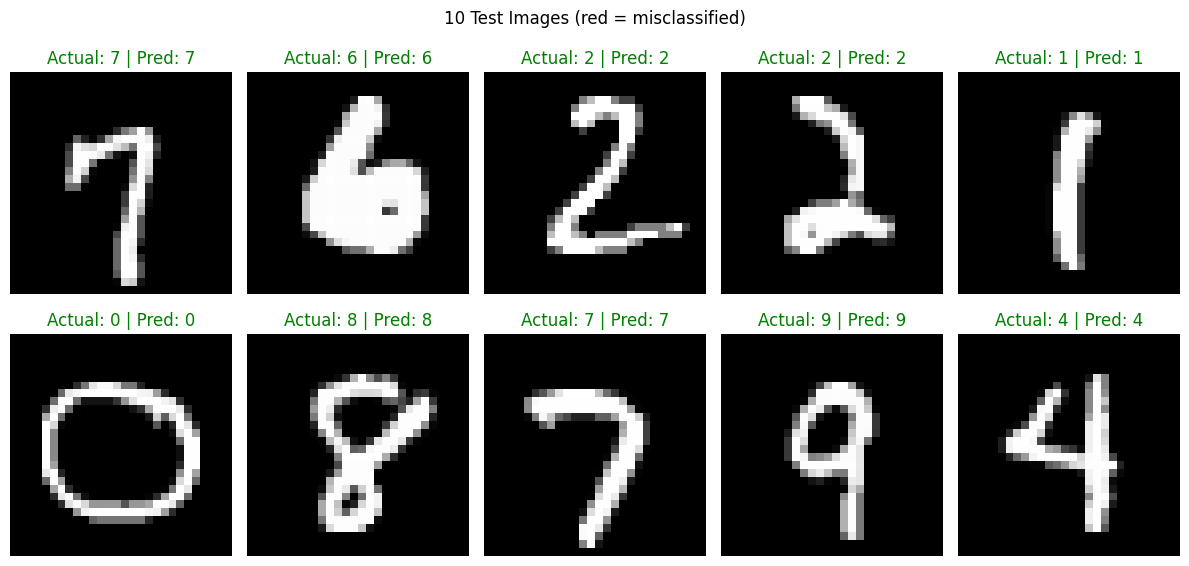

In [26]:
# 11. Test the best learning-rate model on 10 labeled test images
# Keep the learned weights for each learning-rate experiment, then use the
# model with the highest validation accuracy for this test.
best_learning_rate_result = max(
    learning_rate_results,
    key=lambda item: item["Final Validation Accuracy"],
)

test_df = pd.read_csv("Data/mnist_test.csv")
y_test = test_df["label"].to_numpy()
x_test = test_df.drop("label", axis=1).to_numpy() / 255.0

sample_rng = np.random.default_rng(42)
sample_indices = sample_rng.choice(len(x_test), size=10, replace=False)
x_sample = x_test[sample_indices]
y_sample = y_test[sample_indices]

test_probabilities, _, _ = forward_pass(
    x_sample,
    best_learning_rate_result["W1"],
    best_learning_rate_result["B1"],
    best_learning_rate_result["W2"],
    best_learning_rate_result["B2"],
)
predicted_labels = np.argmax(test_probabilities, axis=1)
is_misclassified = predicted_labels != y_sample

print(f"Using learning rate {best_learning_rate_result['Learning Rate']} (best validation accuracy).")
print("Results for 10 randomly selected test images:")
for sample_number, (test_index, actual, predicted, wrong) in enumerate(
    zip(sample_indices, y_sample, predicted_labels, is_misclassified),
    start=1,
):
    status = "MISCLASSIFIED" if wrong else "Correct"
    print(f"Sample {sample_number} (test row {test_index}): actual={actual}, predicted={predicted} - {status}")

misclassified_positions = np.flatnonzero(is_misclassified)
if len(misclassified_positions) == 0:
    print("No misclassifications among these 10 test images.")
else:
    print("\nMisclassified test images:")
    for position in misclassified_positions:
        print(
            f"Test row {sample_indices[position]}: "
            f"actual={y_sample[position]}, predicted={predicted_labels[position]}"
        )

# Display all 10 images; incorrect predictions are highlighted in red.
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for position, ax in enumerate(axes.flat):
    color = "red" if is_misclassified[position] else "green"
    ax.imshow(x_sample[position].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"Actual: {y_sample[position]} | Pred: {predicted_labels[position]}",
        color=color,
    )
    ax.axis("off")

fig.suptitle("10 Test Images (red = misclassified)")
plt.tight_layout()
plt.show()
